# Proyecto final — Éxito de videojuegos en Steam
## Análisis exploratorio de datos (EDA)

**Aprendizaje de Máquina — ITAM**

**Pregunta del proyecto:** ¿qué características disponibles al momento del lanzamiento se relacionan con la recepción de un videojuego en Steam?

El propósito de este notebook es conocer la información, detectar problemas de calidad y explorar relaciones útiles para el modelado. 


## 1. Importación de librerías

Usaremos principalmente `pandas`, `numpy`, `matplotlib` y `seaborn`. 

In [2]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import ast
import json
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 80)
sns.set_theme(style="whitegrid")

SEMILLA = 2026
FECHA_CORTE = pd.Timestamp("2026-11-22")  # Fecha de referencia del análisis

## 2. Carga y comprensión de los archivos

El ZIP contiene `steam_games.csv` y `steam_games_reviews.csv`. La unidad de observación del archivo principal es el **juego (`app_id`)**. El segundo archivo es complementario y no se necesita para construir la variable objetivo porque el archivo principal ya tiene los conteos `positive` y `negative`.


In [2]:
RUTA_ZIP = Path("archive (1).zip")
if not RUTA_ZIP.exists():
    RUTA_ZIP = Path("/mnt/data/archive (1).zip")
if not RUTA_ZIP.exists():
    raise FileNotFoundError("No se encontró el ZIP. Actualiza la variable RUTA_ZIP.")

with zipfile.ZipFile(RUTA_ZIP) as z:
    print("Archivos disponibles:", z.namelist())

columnas_eda = [
    "app_id", "name", "release_date", "price", "price_status",
    "estimated_owners", "developers", "publishers", "genres",
    "categories", "tags", "positive", "negative", "recommendations",
    "peak_ccu", "metacritic_score", "user_score", "average_playtime_forever",
    "achievements", "dlc_count", "supported_languages", "windows",
    "mac", "linux", "steam_store_available", "steam_spy_available"
]

with zipfile.ZipFile(RUTA_ZIP) as z:
    with z.open("steam_games.csv") as archivo:
        df = pd.read_csv(archivo, usecols=columnas_eda, low_memory=False)

print(f"Dimensiones de la base principal: {df.shape[0]:,} filas y {df.shape[1]} columnas seleccionadas")
print("Las 42 columnas originales se conservan en el CSV dentro del ZIP.")
display(df.head(3))

Archivos disponibles: ['steam_games.csv', 'steam_games_reviews.csv']
Dimensiones de la base principal: 145,257 filas y 26 columnas seleccionadas
Las 42 columnas originales se conservan en el CSV dentro del ZIP.


,app_id,name,release_date,price,price_status,estimated_owners,developers,publishers,genres,categories,tags,positive,negative,recommendations,peak_ccu,metacritic_score,user_score,average_playtime_forever,achievements,dlc_count,supported_languages,windows,mac,linux,steam_store_available,steam_spy_available
0,2527550,Roll The Bones,2026-07-28,9.99,paid,"0 .. 20,000","[""Shrimp Industries""]","[""Proteus Interactive""]","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ""70"", ""description"": ""Early Ac...","[{""id"": 2, ""description"": ""Single-player""}, {""id"": 28, ""description"": ""Full ...",[],0,0,NaN,0,NaN,0,0,NaN,0,"English, French, Italian, Spanish - Spain, Dutch, Japanese, Korean, Polish, ...",True,False,False,True,True
1,2806050,Halo: Campaign Evolved,2026-07-28,49.99,paid,"0 .. 20,000","[""Halo Studios""]","[""Xbox Game Studios""]","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ""25"", ""description"": ""Adventur...","[{""id"": 2, ""description"": ""Single-player""}, {""id"": 1, ""description"": ""Multi-...",[],0,0,4936.0,0,NaN,0,0,58.0,1,"English<strong>*</strong>, French<strong>*</strong>, Italian<strong>*</stron...",True,False,False,True,True
2,2789980,Sinned Arena,2026-07-28,8.99,paid,"0 .. 20,000","[""xDenny""]","[""xDenny""]","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ""23"", ""description"": ""Indie""}]","[{""id"": 2, ""description"": ""Single-player""}, {""id"": 1, ""description"": ""Multi-...",[],0,0,NaN,0,NaN,0,0,24.0,0,"English<strong>*</strong>, German, Czech, Polish, Portuguese - Portugal<br><...",True,False,False,True,True


In [3]:
# Revisamos la estructura del archivo de reseñas sin cargarlo completo.
with zipfile.ZipFile(RUTA_ZIP) as z:
    with z.open("steam_games_reviews.csv") as archivo:
        muestra_resenas = pd.read_csv(archivo, nrows=5)

print("Columnas del archivo complementario:", muestra_resenas.columns.tolist())
display(muestra_resenas[["app_id", "name"]].head())
print("Ejemplo de contenido de 'reviews' (primeros 300 caracteres):")
print(str(muestra_resenas.loc[0, "reviews"])[:300])

Columnas del archivo complementario: ['app_id', 'name', 'reviews']


,app_id,name
0,344410,Magnetic: Cage Closed
1,344480,Quell
2,344500,Three Fourths Home: Extended Edition
3,344630,Princess Evangile All Ages Version
4,344740,CRYPTARK


Ejemplo de contenido de 'reviews' (primeros 300 caracteres):
“By the end of Magnetic: Cage Closed, you can forget portals; you’ll be thinking with magnets.” 4/5 – Harcore gamer “A fun and ingenious adventure.” 8.4/10 – IGN Italy “Interesting puzzles and a plot that keeps us hooked” 7.5/10 – IGN Spain 


## 3. Exploración inicial

Primero comprobamos la unicidad de `app_id`, los tipos de datos y las estadísticas descriptivas. Estas revisiones ayudan a detectar problemas antes de modificar la base.

In [4]:
print("Filas:", len(df))
print("app_id únicos:", df["app_id"].nunique())
print("Duplicados por app_id:", df.duplicated(subset="app_id").sum())
print("Duplicados completos:", df.duplicated().sum())
df.info()

Filas: 145257
app_id únicos: 145257
Duplicados por app_id: 0
Duplicados completos: 0
<class 'pandas.DataFrame'>
RangeIndex: 145257 entries, 0 to 145256
Data columns (total 26 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   app_id                    145257 non-null  int64  
 1   name                      145241 non-null  str    
 2   release_date              145175 non-null  str    
 3   price                     143886 non-null  float64
 4   price_status              145257 non-null  str    
 5   estimated_owners          145257 non-null  str    
 6   developers                145257 non-null  str    
 7   publishers                145257 non-null  str    
 8   genres                    145257 non-null  str    
 9   categories                145257 non-null  str    
 10  tags                      145257 non-null  str    
 11  positive                  145257 non-null  int64  
 12  negative                  

In [5]:
display(df.describe().T.round(2))
display(df[["price_status", "estimated_owners", "steam_store_available", "steam_spy_available"]].describe(include="all").T)

,count,mean,std,min,25%,50%,75%,max
app_id,145257.0,2336928.88,1328303.72,10.0,1207520.00,2231920.00,3372980.00,5423900.0
price,143886.0,8.97,403.21,0.0,0.99,4.99,9.99,107500.0
positive,145257.0,882.39,25811.98,0.0,0.00,2.00,25.00,7642084.0
negative,145257.0,142.97,4938.34,0.0,0.00,0.00,7.00,1173003.0
recommendations,101355.0,1225.30,25276.75,0.0,0.00,0.00,0.00,5179195.0
peak_ccu,145257.0,46.14,3426.55,0.0,0.00,0.00,0.00,1013936.0
metacritic_score,92822.0,3.42,15.71,0.0,0.00,0.00,0.00,97.0
user_score,145257.0,0.02,1.28,0.0,0.00,0.00,0.00,100.0
average_playtime_forever,145257.0,62.35,1820.89,0.0,0.00,0.00,0.00,359665.0
achievements,122407.0,21.23,150.52,0.0,0.00,9.00,22.00,10979.0


,count,unique,top,freq
price_status,145257,3,paid,115615
estimated_owners,145257,27,0 - 20000,56505
steam_store_available,145257,2,True,145243
steam_spy_available,145257,1,True,145257


## 4. Calidad de los datos

Analizamos los faltantes **antes de imputar o eliminar registros**. Algunas columnas dependen de que Steam Store o SteamSpy hayan respondido a la extracción, por lo que una ausencia podría reflejar problemas de cobertura y no un valor igual a cero.

,faltantes,porcentaje
metacritic_score,52435,36.10
recommendations,43902,30.22
achievements,22850,15.73
price,1371,0.94
release_date,82,0.06
supported_languages,28,0.02
name,16,0.01
linux,14,0.01
windows,14,0.01
mac,14,0.01


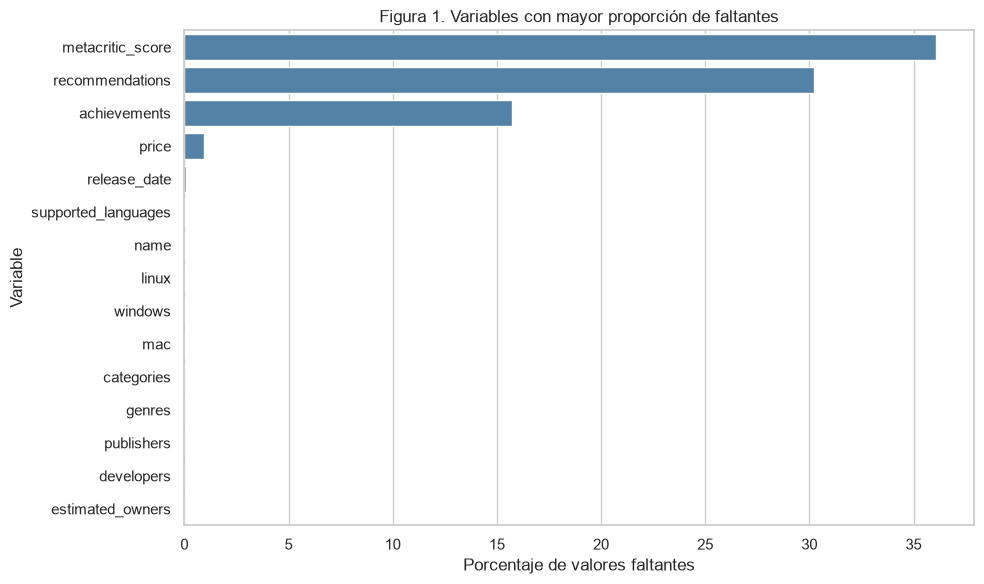

In [6]:
faltantes = (
    df.isna().sum()
    .rename("faltantes")
    .to_frame()
)
faltantes["porcentaje"] = 100 * faltantes["faltantes"] / len(df)
faltantes = faltantes.sort_values("porcentaje", ascending=False)
display(faltantes.round(2))

plt.figure(figsize=(10, 6))
sns.barplot(data=faltantes.head(15).reset_index(), x="porcentaje", y="index", color="steelblue")
plt.title("Figura 1. Variables con mayor proporción de faltantes")
plt.xlabel("Porcentaje de valores faltantes")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

In [7]:
disponibilidad = (
    df.groupby(["steam_store_available", "steam_spy_available"], dropna=False)
    .size().rename("juegos").reset_index()
)
display(disponibilidad)

# Las cadenas vacías o listas vacías también pueden ocultar ausencia de información.
for variable in ["developers", "publishers", "genres", "categories", "tags", "supported_languages"]:
    vacios = df[variable].astype("string").str.strip().isin(["", "[]", "nan", "None"]).sum()
    print(f"{variable}: {vacios:,} registros vacíos o con lista vacía")

,steam_store_available,steam_spy_available,juegos
0,False,True,14
1,True,True,145243


developers: 8,449 registros vacíos o con lista vacía
publishers: 8,849 registros vacíos o con lista vacía
genres: 8,433 registros vacíos o con lista vacía
categories: 8,962 registros vacíos o con lista vacía
tags: 61,786 registros vacíos o con lista vacía
supported_languages: 8,369 registros vacíos o con lista vacía


### 4.1 Fechas y precios inconsistentes

Convertimos la fecha de lanzamiento y comprobamos fechas inválidas y posteriores a la fecha de referencia. Para los precios, verificamos faltantes y valores negativos. **Los precios son actuales**, así que podrían haber cambiado desde el lanzamiento; por ello su uso como predictor histórico requiere una advertencia adicional.

In [8]:
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
df["price"] = pd.to_numeric(df["price"], errors="coerce")

revisiones = pd.Series({
    "Fecha no válida o ausente": df["release_date"].isna().sum(),
    "Fecha posterior al corte": (df["release_date"] > FECHA_CORTE).sum(),
    "Precio faltante": df["price"].isna().sum(),
    "Precio negativo": (df["price"] < 0).sum(),
    "Sin reseñas positivas ni negativas": ((df["positive"] + df["negative"]) == 0).sum(),
    "Conteos negativos de reseñas": ((df["positive"] < 0) | (df["negative"] < 0)).sum(),
}, name="Número de juegos")
display(revisiones.to_frame())

,Número de juegos
Fecha no válida o ausente,82
Fecha posterior al corte,0
Precio faltante,1371
Precio negativo,0
Sin reseñas positivas ni negativas,62178
Conteos negativos de reseñas,0


## 5. Variable objetivo: proporción de reseñas positivas

Definimos la recepción observada como:

\[
\text{proporción positiva}=\frac{\text{positive}}{\text{positive}+\text{negative}}.
\]

Esta proporción solamente existe cuando el denominador es mayor a cero. En la propuesta inicial se consideró un mínimo de **50 reseñas** para reducir la inestabilidad de proporciones calculadas con muy pocas opiniones. Compararemos umbrales antes de decidir si ese filtro es adecuado.

**Limitación importante:** los conteos son acumulados hasta la fecha de extracción. Los juegos antiguos han tenido más tiempo para recibir opiniones, y los juegos con pocas reseñas pueden quedar subrepresentados.

,mínimo_reseñas,juegos,porcentaje_del_total
0,1,83079,57.19
1,10,56772,39.08
2,20,44663,30.75
3,50,30697,21.13
4,100,22860,15.74
5,500,10535,7.25


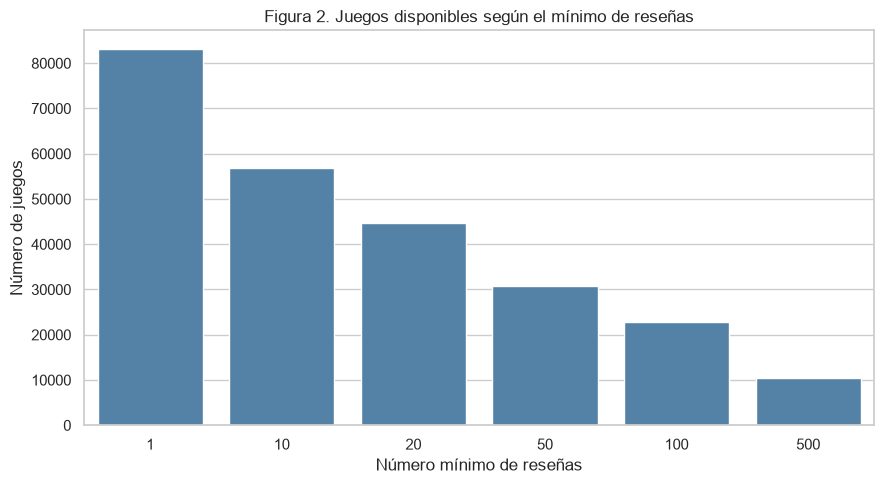

In [9]:
df["total_resenas"] = df["positive"] + df["negative"]
df["prop_positivas"] = np.where(
    df["total_resenas"] > 0,
    df["positive"] / df["total_resenas"],
    np.nan
)

umbrales = [1, 10, 20, 50, 100, 500]
comparacion_umbrales = pd.DataFrame({
    "mínimo_reseñas": umbrales,
    "juegos": [(df["total_resenas"] >= u).sum() for u in umbrales]
})
comparacion_umbrales["porcentaje_del_total"] = (
    100 * comparacion_umbrales["juegos"] / len(df)
)
display(comparacion_umbrales.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(data=comparacion_umbrales, x="mínimo_reseñas", y="juegos", color="steelblue")
plt.title("Figura 2. Juegos disponibles según el mínimo de reseñas")
plt.xlabel("Número mínimo de reseñas")
plt.ylabel("Número de juegos")
plt.tight_layout()
plt.show()

Con al menos 50 reseñas quedan 30,697 juegos (21.1% de la base).


count    30697.000
mean         0.785
std          0.155
min          0.071
25%          0.700
50%          0.820
75%          0.905
max          1.000
Name: prop_positivas, dtype: float64

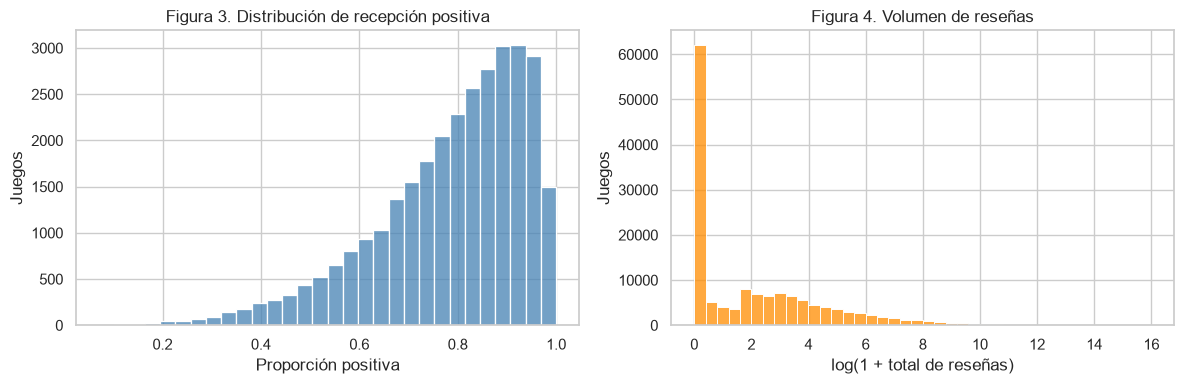

In [10]:
df_50 = df.loc[df["total_resenas"] >= 50].copy()
print(f"Con al menos 50 reseñas quedan {len(df_50):,} juegos ({len(df_50)/len(df):.1%} de la base).")
display(df_50["prop_positivas"].describe().round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_50["prop_positivas"], bins=30, ax=axes[0], color="steelblue")
axes[0].set(title="Figura 3. Distribución de recepción positiva", xlabel="Proporción positiva", ylabel="Juegos")
sns.histplot(np.log1p(df["total_resenas"]), bins=40, ax=axes[1], color="darkorange")
axes[1].set(title="Figura 4. Volumen de reseñas", xlabel="log(1 + total de reseñas)", ylabel="Juegos")
plt.tight_layout()
plt.show()

## 6. Análisis univariado de características de lanzamiento

Exploramos precio, año de lanzamiento y plataformas. La idea es conocer la distribución de posibles predictores sin confundir asociación con causalidad.

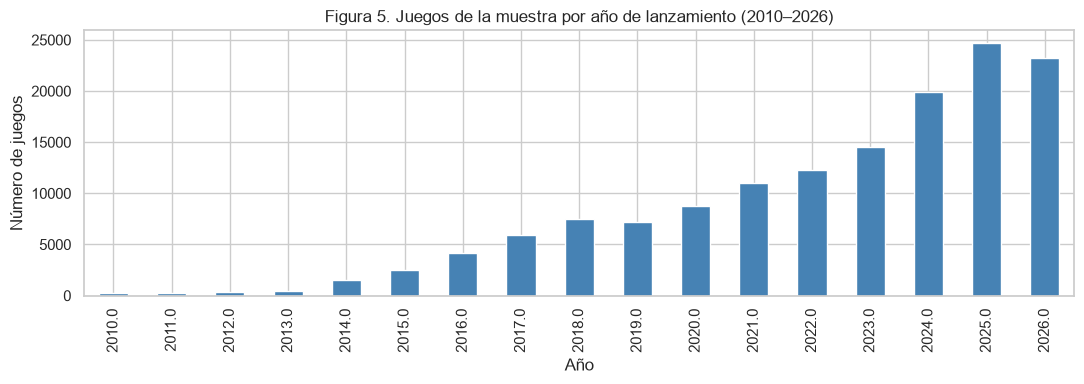

count    143886.00
mean          8.97
std         403.21
min           0.00
25%           0.99
50%           4.99
75%           9.99
90%          16.48
95%          19.99
99%          49.99
max      107500.00
Name: price, dtype: float64

In [11]:
df["anio_lanzamiento"] = df["release_date"].dt.year
df["mes_lanzamiento"] = df["release_date"].dt.month

juegos_anio = df["anio_lanzamiento"].value_counts().sort_index()
juegos_anio = juegos_anio.loc[(juegos_anio.index >= 2010) & (juegos_anio.index <= 2026)]

plt.figure(figsize=(11, 4))
juegos_anio.plot(kind="bar", color="steelblue")
plt.title("Figura 5. Juegos de la muestra por año de lanzamiento (2010–2026)")
plt.xlabel("Año")
plt.ylabel("Número de juegos")
plt.tight_layout()
plt.show()

display(df["price"].describe(percentiles=[.25, .5, .75, .9, .95, .99]).round(2))

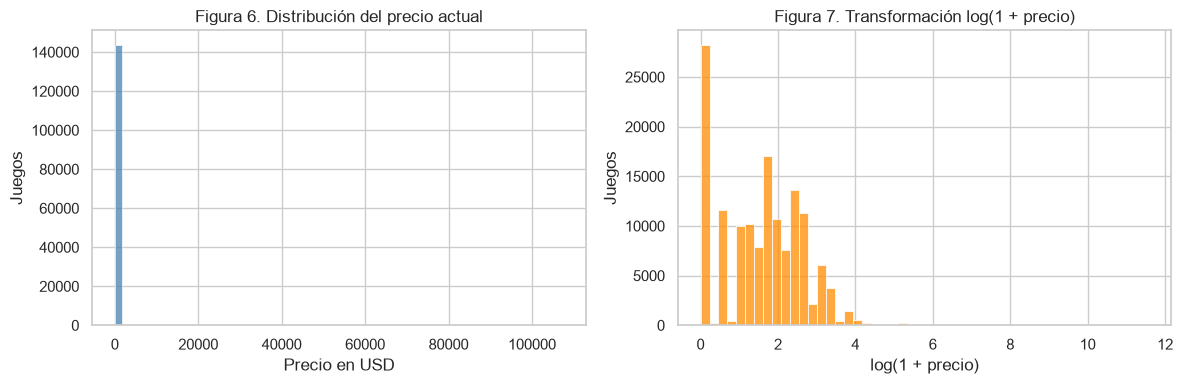

,Juegos con soporte
windows,145179
mac,24556
linux,18558


In [12]:
precios = df.loc[df["price"].notna() & (df["price"] >= 0), "price"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(precios, bins=60, ax=axes[0], color="steelblue")
axes[0].set(title="Figura 6. Distribución del precio actual", xlabel="Precio en USD", ylabel="Juegos")
sns.histplot(np.log1p(precios), bins=50, ax=axes[1], color="darkorange")
axes[1].set(title="Figura 7. Transformación log(1 + precio)", xlabel="log(1 + precio)", ylabel="Juegos")
plt.tight_layout()
plt.show()

plataformas = df[["windows", "mac", "linux"]].sum().sort_values(ascending=False)
display(plataformas.rename("Juegos con soporte").to_frame())

`log1p(precio)` puede ser útil si la distribución está muy concentrada en valores pequeños. Aun así, el precio del archivo es el **precio observado en la extracción**, no necesariamente el precio original de lanzamiento. No debemos presentarlo como una variable histórica perfectamente conocida.

## 7. Géneros, categorías y desarrolladores

Algunas columnas contienen listas representadas como texto, y sus elementos pueden ser diccionarios con etiquetas. Es preferible interpretarlas con una función que soporte ambos formatos en lugar de dividir las cadenas por comas (los nombres pueden contener comas).

In [13]:
def leer_lista(valor):
    """Convierte una lista almacenada como texto en una lista de Python."""
    if isinstance(valor, list):
        return valor
    if pd.isna(valor) or str(valor).strip() in ("", "[]"):
        return []
    for parser in (json.loads, ast.literal_eval):
        try:
            resultado = parser(valor)
            return resultado if isinstance(resultado, list) else []
        except (ValueError, SyntaxError, TypeError, json.JSONDecodeError):
            pass
    return []


def extraer_etiquetas(valor):
    """Recupera descripciones en diccionarios o nombres en listas de texto."""
    elementos = leer_lista(valor)
    etiquetas = []
    for elemento in elementos:
        if isinstance(elemento, dict):
            etiqueta = elemento.get("description", elemento.get("name"))
        else:
            etiqueta = elemento
        if etiqueta is not None and str(etiqueta).strip():
            etiquetas.append(str(etiqueta).strip())
    return etiquetas

for col in ["genres", "categories", "developers", "publishers"]:
    df[f"lista_{col}"] = df[col].apply(extraer_etiquetas)
    df[f"n_{col}"] = df[f"lista_{col}"].apply(len)

# Validación rápida del formato y de las etiquetas recuperadas.
display(df[["name", "lista_genres", "lista_categories", "lista_developers"]].head(5))

,name,lista_genres,lista_categories,lista_developers
0,Roll The Bones,"[Action, Early Access]","[Single-player, Full controller support, DualShock Controller Support, DualS...",[Shrimp Industries]
1,Halo: Campaign Evolved,"[Action, Adventure]","[Single-player, Multi-player, Co-op, Online Co-op, Steam Achievements, Full ...",[Halo Studios]
2,Sinned Arena,"[Action, Indie]","[Single-player, Multi-player, PvP, Online PvP, LAN PvP, Steam Achievements, ...",[xDenny]
3,Go North,"[Adventure, Casual, Indie]","[Single-player, Full controller support, DualShock Controller Support, DualS...",[gazuntype]
4,Rabbit Comes Home,"[Action, Adventure]","[Single-player, Steam Achievements, Steam Cloud, Family Sharing]",[ZIPSTED]


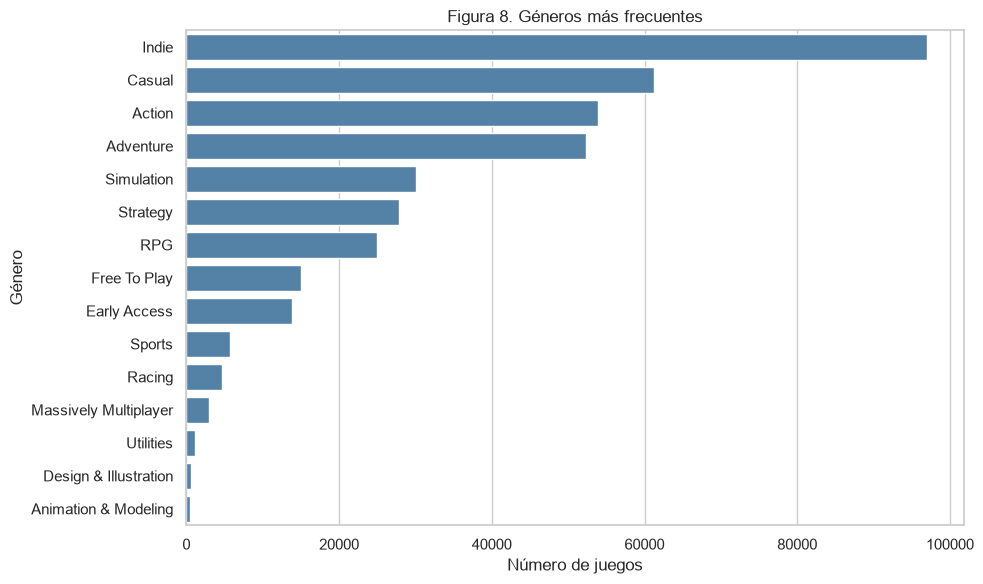

,n_genres,n_categories,n_developers
count,145257.00,145257.00,145257.00
mean,2.72,4.63,1.03
std,1.46,3.47,0.56
min,0.00,0.00,0.00
25%,2.00,2.00,1.00
50%,3.00,4.00,1.00
75%,4.00,6.00,1.00
max,19.00,34.00,41.00


In [14]:
from collections import Counter

conteo_generos = Counter(g for lista in df["lista_genres"] for g in set(lista))
top_generos = pd.Series(conteo_generos).sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_generos.values, y=top_generos.index, color="steelblue")
plt.title("Figura 8. Géneros más frecuentes")
plt.xlabel("Número de juegos")
plt.ylabel("Género")
plt.tight_layout()
plt.show()

display(df[["n_genres", "n_categories", "n_developers"]].describe().round(2))

La codificación **multi-hot** puede representar los géneros y categorías: un mismo juego puede pertenecer a varios grupos.

## 8. Idiomas disponibles

`'supported_languages'` aparece como texto (en algunas observaciones contiene marcas HTML). El conteo exacto requiere una limpieza cuidadosa; por ahora revisamos ejemplos y calculamos una aproximación, que posteriormente validaremos antes de incorporarla como variable predictora.

,name,supported_languages
0,Roll The Bones,"English, French, Italian, Spanish - Spain, Dutch, Japanese, Korean, Polish, ..."
1,Halo: Campaign Evolved,"English<strong>*</strong>, French<strong>*</strong>, Italian<strong>*</stron..."
2,Sinned Arena,"English<strong>*</strong>, German, Czech, Polish, Portuguese - Portugal<br><..."
3,Go North,English<strong>*</strong><br><strong>*</strong>languages with full audio sup...
4,Rabbit Comes Home,"English, French, Italian, German, Spanish - Spain, Japanese, Russian, Simpli..."


count    145257.00
mean          5.52
std          13.59
min           0.00
25%           1.00
50%           1.00
75%           5.00
max         103.00
Name: n_idiomas_aprox, dtype: float64

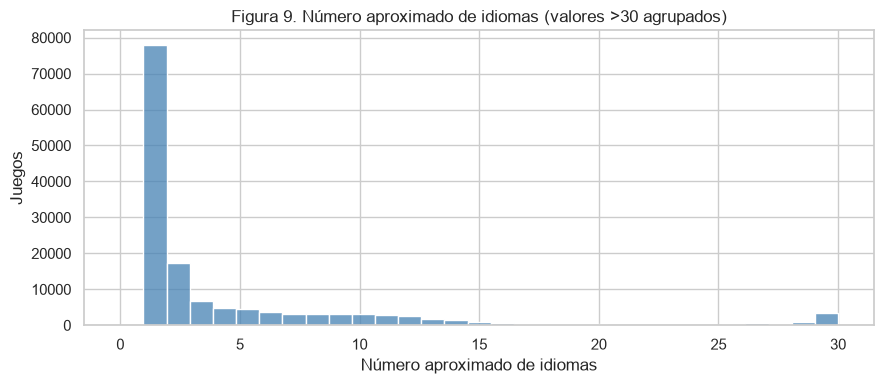

In [15]:
display(df[["name", "supported_languages"]].head(5))

# Aproximación preliminar: separadores por coma, tras limpiar etiquetas HTML.
idiomas_limpios = (
    df["supported_languages"]
    .fillna("")
    .astype(str)
    .str.replace(r"<[^>]+>", "", regex=True)
    .str.replace(r"\*", "", regex=True)
)
df["n_idiomas_aprox"] = idiomas_limpios.apply(
    lambda x: len([i for i in x.split(",") if i.strip()]) if x.strip() else 0
)
display(df["n_idiomas_aprox"].describe().round(2))

plt.figure(figsize=(9, 4))
sns.histplot(df["n_idiomas_aprox"].clip(upper=30), bins=31, color="steelblue")
plt.title("Figura 9. Número aproximado de idiomas (valores >30 agrupados)")
plt.xlabel("Número aproximado de idiomas")
plt.ylabel("Juegos")
plt.tight_layout()
plt.show()

## 9. Relaciones con la recepción

Para explorar asociaciones utilizamos temporalmente los juegos con 50 o más reseñas. 

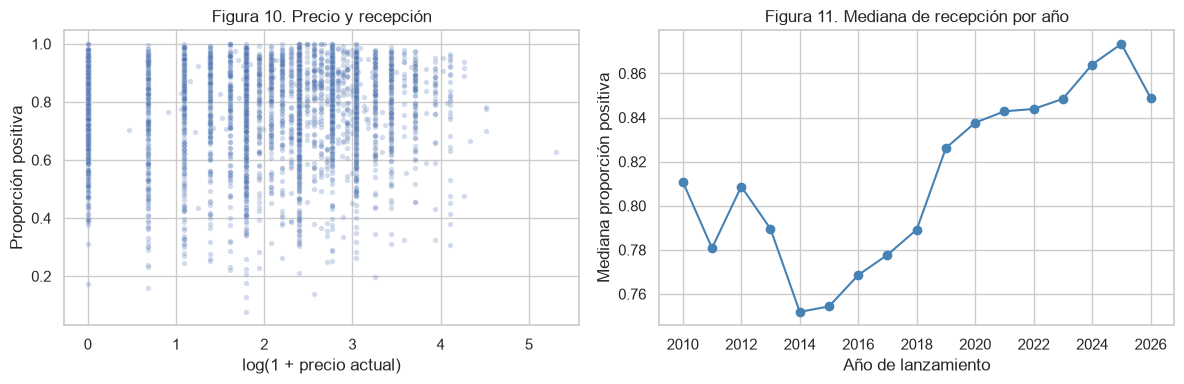

In [16]:
df_50 = df.loc[df["total_resenas"] >= 50].copy()
df_50["log_precio"] = np.log1p(df_50["price"].clip(lower=0))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=df_50.sample(min(len(df_50), 4000), random_state=SEMILLA),
                x="log_precio", y="prop_positivas", alpha=.25, s=15, ax=axes[0])
axes[0].set(title="Figura 10. Precio y recepción", xlabel="log(1 + precio actual)", ylabel="Proporción positiva")
mediana_anual = df_50.groupby("anio_lanzamiento")["prop_positivas"].median()
mediana_anual = mediana_anual.loc[(mediana_anual.index >= 2010) & (mediana_anual.index <= 2026)]
mediana_anual.plot(ax=axes[1], marker="o", color="steelblue")
axes[1].set(title="Figura 11. Mediana de recepción por año", xlabel="Año de lanzamiento", ylabel="Mediana proporción positiva")
plt.tight_layout()
plt.show()

,juegos,mediana_recepcion
lista_genres,,
Indie,21117,0.824
Adventure,13226,0.825
Action,12896,0.804
Casual,10305,0.834
Simulation,7366,0.796
RPG,6866,0.807
Strategy,6693,0.794
Free To Play,2690,0.791
Early Access,2059,0.765


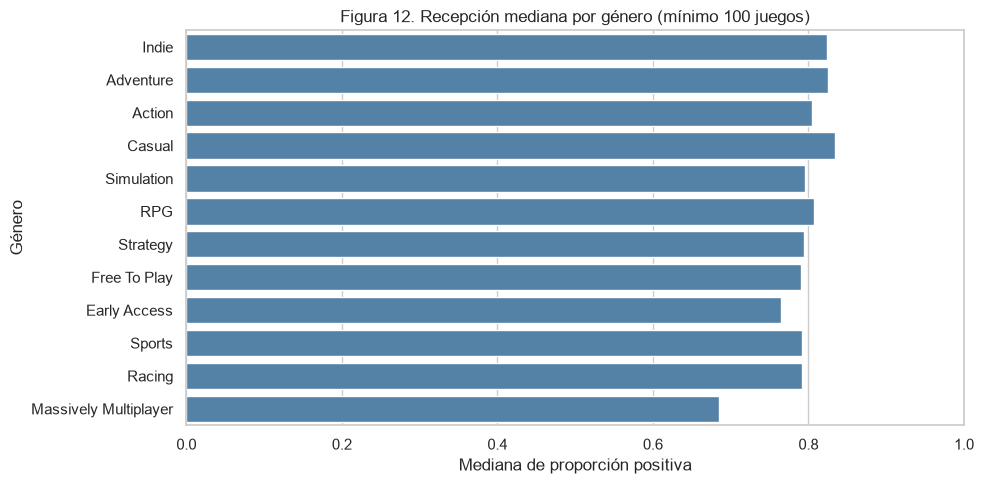

In [17]:
# Comparación por género. Un juego puede aparecer en varios géneros.
generos_expandidos = df_50[["app_id", "prop_positivas", "lista_genres"]].explode("lista_genres")
resumen_generos = (
    generos_expandidos.groupby("lista_genres", dropna=True)
    .agg(juegos=("app_id", "nunique"), mediana_recepcion=("prop_positivas", "median"))
    .query("juegos >= 100")
    .sort_values("juegos", ascending=False)
)
display(resumen_generos.head(15).round(3))

plt.figure(figsize=(10, 5))
sns.barplot(data=resumen_generos.head(12).reset_index(),
            x="mediana_recepcion", y="lista_genres", color="steelblue")
plt.title("Figura 12. Recepción mediana por género (mínimo 100 juegos)")
plt.xlabel("Mediana de proporción positiva")
plt.ylabel("Género")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

## 10. Historial del desarrollador y riesgo de fuga de información

Una parte distintiva de la propuesta es usar la experiencia previa de cada estudio. La variable debe calcularse **en orden cronológico**, sin contar juegos publicados posteriormente. Además, no basta con que un juego sea anterior: sus reseñas acumuladas en la extracción también pueden contener opiniones que todavía no existían al momento de lanzar otro juego.

Por lo tanto, en este EDA exploramos la cantidad de títulos anteriores.

In [18]:
# En desarrolladores con varios juegos, contamos lanzamientos previos por fecha.
# Los juegos del mismo día no se consideran antecedentes entre sí.
explosion = df[["app_id", "release_date", "lista_developers"]].explode("lista_developers")
explosion = explosion.dropna(subset=["release_date", "lista_developers"]).copy()
explosion = explosion.rename(columns={"lista_developers": "desarrollador"})
explosion = explosion.drop_duplicates(subset=["app_id", "desarrollador"])

conteos_dia = (
    explosion.groupby(["desarrollador", "release_date"])
    .size().rename("lanzamientos_dia").reset_index()
    .sort_values(["desarrollador", "release_date"])
)
conteos_dia["juegos_previos"] = (
    conteos_dia.groupby("desarrollador")["lanzamientos_dia"].cumsum()
    - conteos_dia["lanzamientos_dia"]
)
explosion = explosion.merge(
    conteos_dia[["desarrollador", "release_date", "juegos_previos"]],
    on=["desarrollador", "release_date"], how="left", validate="many_to_one"
)

historial = explosion.groupby("app_id")["juegos_previos"].max().rename("max_juegos_previos_desarrollador")
df = df.join(historial, on="app_id")
df["max_juegos_previos_desarrollador"] = df["max_juegos_previos_desarrollador"].fillna(0).astype(int)
display(df["max_juegos_previos_desarrollador"].describe(percentiles=[.5, .9, .99]).round(2))

count    145257.00
mean          3.49
std          13.11
min           0.00
50%           0.00
90%           6.00
99%          70.00
max         236.00
Name: max_juegos_previos_desarrollador, dtype: float64

**Interpretación:** el conteo de lanzamientos anteriores es una aproximación útil a la experiencia del desarrollador. Si hay varios desarrolladores usamos el máximo, pero es una decisión de diseño que debe compararse con alternativas (promedio o suma). 